# Language transfer of workspace lenses: report figures and tables

This notebook produces only what goes into the report. Every figure is saved to `figures/` as PDF and PNG, **without title or caption** (those are written in the report). After each result, an *Analysis* paragraph and *Key points* say what to take from it.

The numbers quoted in the text are for **Qwen3.5-9B, 1,000 fitting prompts**. To get the 27B versions, point `ROOT` to that archive and rerun; section 6 needs the `scores/` folder and is skipped when it is absent.

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

MODEL_27B = False

ROOT = Path("language_transfer_results")   # extracted archive: holds lang/ and, for 9B, scores/
if MODEL_27B:
    ROOT = Path("language_transfer_results_27b")   # extracted archive: holds lang/ and, for 27B, scores/
FIGURES = Path("figures")
if MODEL_27B:
    FIGURES = Path("figures_27b")
FIGURES.mkdir(exist_ok=True)

RUN = ["lens", "fit", "pool"]                 # which lens
CONDITION = ["prompt_lang", "target_lang"]    # how it is read
COLUMNS = [("en", "en"), ("en", "fr"), ("fr", "en"), ("fr", "fr")]
OTHER = {"en": "fr", "fr": "en"}
LENS_NAMES = {"j": "J", "r": "R", "jpp_matched": "J++ matched", "jpp_wen": "J++ EN weights",
              "jpp_wfr": "J++ FR weights", "jpp": "J++ original"}
BLUE, ORANGE, GREY, INK = "#2a6fb0", "#d98b1f", "#8a8a8a", "#1a1a1a"

def save(figure, name):
    for extension in ("pdf", "png"):
        figure.savefig(FIGURES / f"{name}.{extension}", dpi=200, bbox_inches="tight")

def clean(axis):
    axis.grid(axis="x", color="#dddddd", linewidth=0.8)
    axis.set_axisbelow(True)
    for side in ("top", "right", "left"):
        axis.spines[side].set_visible(False)
    axis.tick_params(axis="y", length=0)

## 1. Data, filters and scores

**Benchmark.** Parallel items: the same concept as an English and a French prompt, with the hidden intermediate as an English and a French word (*Brazil* / *Brésil*). Each is read under four conditions, prompt language x target language. The 17 upstream French multilingual items are kept as a second group.

**Filters.** Held-out items only; the model answers correctly in every prompt language used; the concept is a different word in the two languages; both words are single tokens.

**Scores**, per item and condition:
- `hit`: recall@10, 1 if the word is in the lens's top 10 at its best layer;
- `log_rank`: log2 of its best rank over layers (lower is better, 1 bit = a factor of two);
- `lift`: log2 rank of the same word at unrelated prompts (its *baseline*) minus `log_rank` (higher is better). It removes whatever the lens ranks high regardless of the prompt.

**Uncertainty.** 95% intervals from 5,000 bootstrap resamples of items, stratified by task and shared by all lenses, so differences between cells are paired.

In [37]:
LANG = ROOT / "lang"
records = json.loads((LANG / "items.json").read_text())
words = {(r["name"], l): r[l]["intermediates"] for r in records for l in ("en", "fr")}
ranks = pd.read_csv(LANG / "ranks.csv")

# Best rank over layers, then the four filters
keys = RUN + ["group", "split", "eval", "item"] + CONDITION + ["position", "intermediate"]
scored = ranks.groupby(keys, as_index=False)["rank"].min().rename(columns={"rank": "best_rank"})
funnel = {"scored": scored["item"].nunique()}
scored = scored[scored["split"] == "held-out"]
funnel["held-out"] = scored["item"].nunique()

correct = {}
for language in ("en", "fr"):
    frame = pd.read_csv(LANG / f"correctness_{language}.csv")
    grade = frame.iloc[:, 2]
    correct[language] = set(frame["item"][grade.isna() | (grade.astype(str) == "True")])
needed = {"parallel": ("en", "fr"), "fr-multilingual": ("fr",)}
scored = scored[[all(i in correct[l] for l in needed[g]) for i, g in zip(scored["item"], scored["group"])]]
funnel["answered correctly"] = scored["item"].nunique()

same = [words[(i, "en")][p].casefold() == words[(i, "fr")][p].casefold() for i, p in zip(scored["item"], scored["position"])]
scored = scored[~np.array(same)]
both = scored.groupby(["item", "position"])["target_lang"].nunique()
both = set(both[both == 2].index)
scored = scored[[(i, p) in both for i, p in zip(scored["item"], scored["position"])]].copy()
funnel["scoreable in both languages"] = scored["item"].nunique()

print(pd.Series(funnel, name="items").to_string())
print(scored.drop_duplicates(["item", "position"]).groupby(["group", "eval"]).agg(items=("item", "nunique"), concepts=("position", "size")))

scored                         109
held-out                        76
answered correctly              62
scoreable in both languages     56
                              items  concepts
group           eval                         
fr-multilingual multilingual     12        45
parallel        association      20        20
                multihop         24        24


In [38]:
# Scores
scored["hit"] = (scored["best_rank"] <= 10).astype(float)
scored["log_rank"] = np.log2(scored["best_rank"])

baseline = pd.read_csv(LANG / "baseline_ranks.csv")
baseline["baseline"] = np.log2(baseline["best_rank"])
baseline = baseline.groupby(RUN + ["group"] + CONDITION + ["word"], as_index=False)["baseline"].mean()
scored = scored.merge(baseline.rename(columns={"word": "intermediate"}), on=RUN + ["group"] + CONDITION + ["intermediate"], how="left")
scored["lift"] = scored["baseline"] - scored["log_rank"]

def add_matched(frame):
    # jpp_matched: J++ whose expert weights were fitted on labels in the language of its own corpus
    english = frame["fit"].isin(["wikitext", "en"])
    matched = frame[((frame["lens"] == "jpp_wen") & english) | ((frame["lens"] == "jpp_wfr") & (frame["fit"] == "fr"))]
    return pd.concat([frame, matched.assign(lens="jpp_matched")], ignore_index=True)

SCORES = ["hit", "log_rank", "baseline", "lift"]
item_scores = add_matched(scored.groupby(["group", "eval", "item"] + RUN + CONDITION, as_index=False)[SCORES].mean())

def bootstrap(frame, score, n_boot=5000, seed=0, average_pools=True):
    # Point estimate (Series) and bootstrap draws (DataFrame) of every cell: items -> tasks -> pools
    wide = frame.pivot_table(index=["eval", "item"], columns=RUN + CONDITION, values=score)
    assert not wide.isna().any().any(), "some cell is missing items"
    rng = np.random.default_rng(seed)
    tasks = [task.to_numpy() for _, task in wide.groupby(level="eval")]
    point = pd.Series(np.mean([t.mean(axis=0) for t in tasks], axis=0), index=wide.columns)
    draws = pd.DataFrame(np.mean([t[rng.integers(0, len(t), (n_boot, len(t)))].mean(axis=1) for t in tasks], axis=0), columns=wide.columns)
    if average_pools:
        levels = ["lens", "fit"] + CONDITION
        point, draws = point.groupby(level=levels).mean(), draws.T.groupby(level=levels).mean().T
    return point, draws

def interval(value, draws):
    return {"value": value, "low": draws.quantile(0.025), "high": draws.quantile(0.975)}

def difference(result, a, b):
    point, draws = result
    return interval(point[a] - point[b], draws[a] - draws[b])

def text(entry, digits=2, signed=False):
    sign = "+" if signed else ""
    return f"{entry['value']:{sign}.{digits}f} [{entry['low']:{sign}.{digits}f}, {entry['high']:{sign}.{digits}f}]"

parallel = item_scores[item_scores["group"] == "parallel"]
result = {score: bootstrap(parallel, score) for score in SCORES}
N_ITEMS = parallel["item"].nunique()
HAS_POOL_B = "b" in set(parallel["pool"])
print(f"{N_ITEMS} parallel items; pools: {sorted(parallel['pool'].unique())}")

44 parallel items; pools: ['a']


## 2. Performance matrices (Figure 1)

One panel per lens. Rows: the corpus the lens was fitted on, plus the Logit Lens, which involves no fitting. Columns: the four conditions. Black border: the in-domain cell (prompts and targets in the lens's fitting language). Darker is better in both figures.

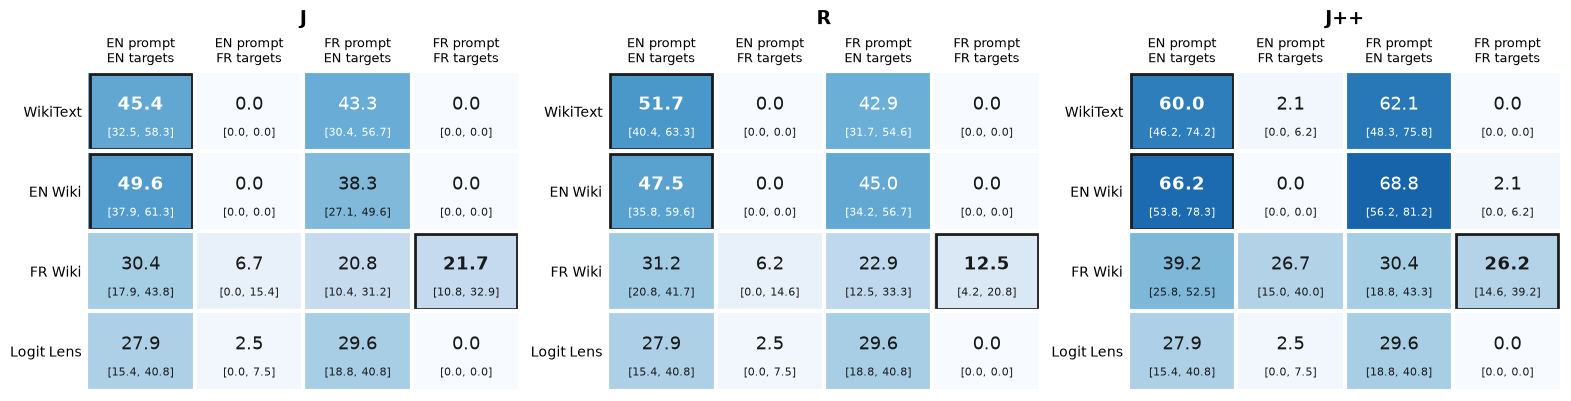

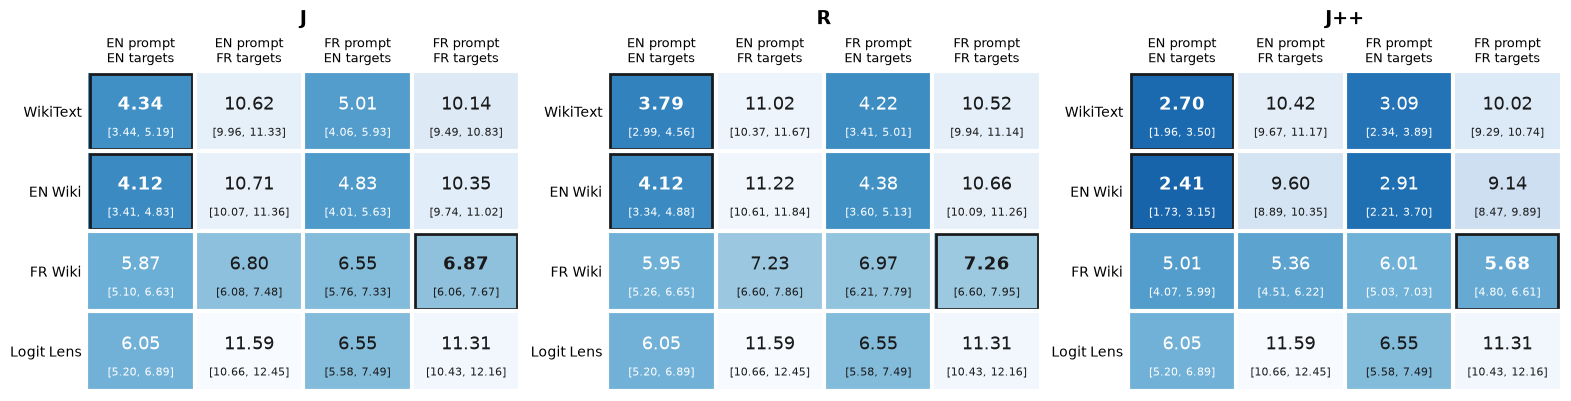

In [39]:
PANELS = [("j", "J"), ("r", "R"), ("jpp_matched", "J++")]
ROWS = [("wikitext", "WikiText"), ("en", "EN Wiki"), ("fr", "FR Wiki")]
IN_DOMAIN = {"wikitext": ("en", "en"), "en": ("en", "en"), "fr": ("fr", "fr")}

def plot_matrix(score, scale=1, digits=1, higher_is_better=True):
    point, draws = result[score]
    value, low, high = point * scale, draws.quantile(0.025) * scale, draws.quantile(0.975) * scale
    figure, axes = plt.subplots(1, len(PANELS), figsize=(5.2 * len(PANELS), 3.9), constrained_layout=True)
    for axis, (lens, name) in zip(axes, PANELS):
        rows = [(lens, fit, label) for fit, label in ROWS] + [("logit", "none", "Logit Lens")]
        grid = np.array([[value[(l, fit, *c)] for c in COLUMNS] for l, fit, _ in rows])
        shade = (grid - value.min()) / (value.max() - value.min())
        shade = shade if higher_is_better else 1 - shade
        axis.imshow(shade, cmap="Blues", vmin=0, vmax=1.25, aspect="auto")
        for i, (l, fit, _) in enumerate(rows):
            for j, c in enumerate(COLUMNS):
                key, ink = (l, fit, *c), "white" if shade[i, j] > 0.6 else INK
                own = IN_DOMAIN.get(fit) == c
                axis.text(j, i - 0.08, f"{value[key]:.{digits}f}", ha="center", va="center", color=ink, fontsize=13,
                          fontweight="bold" if own else "normal")
                axis.text(j, i + 0.27, f"[{low[key]:.{digits}f}, {high[key]:.{digits}f}]", ha="center", va="center", color=ink, fontsize=8)
                if own:
                    axis.add_patch(Rectangle((j - 0.47, i - 0.47), 0.94, 0.94, fill=False, edgecolor=INK, linewidth=2))
        axis.set_xticks(range(4), [f"{p.upper()} prompt\n{t.upper()} targets" for p, t in COLUMNS], fontsize=9)
        axis.xaxis.tick_top()
        axis.set_yticks(range(len(rows)), [label for *_, label in rows], fontsize=10)
        axis.set_xticks(np.arange(-0.5, 4), minor=True)
        axis.set_yticks(np.arange(-0.5, len(rows)), minor=True)
        axis.grid(which="minor", color="white", linewidth=3)
        axis.tick_params(which="both", length=0)
        for spine in axis.spines.values():
            spine.set_visible(False)
        axis.set_title(name, fontsize=14, fontweight="bold", pad=34)
    return figure

save(plot_matrix("hit", scale=100), "fig1a_matrix_recall")
save(plot_matrix("log_rank", digits=2, higher_is_better=False), "fig1b_matrix_logrank")

**Analysis.** On French targets (second and fourth columns) only the French-fitted row is dark: English-fitted lenses and the Logit Lens find a French word in 2.5 to 5% of items, French-fitted lenses in 17.5 to 31%. On English targets every row stays fairly dark, the French-fitted one included. The Logit Lens row is dark only on English targets, for both prompt languages. The two in-domain cells are far apart (J: 56.2% in English, 25.0% in French).

Recall cannot separate the cells near zero, since 2.5% is one item out of 40. Log rank can: the same French-target cells read 8.4 to 9.9 bits for English-fitted lenses against 5.4 to 6.7 for French-fitted ones.

**Key points**
- A lens reads the vocabulary of the language it was fitted on.
- The effect is asymmetric: fitting on French adds French readout without removing English readout.
- With no lens at all, the model's hidden state surfaces English words, even on French prompts.
- Recall@10 saturates on French targets; log rank is the metric to compare lenses there.

## 3. Language, corpus and noise effects (Table 1)

Three paired differences in log2 rank, on the two in-domain conditions. Positive means the first-named lens ranks the hidden word lower.
- **language**: French-fitted minus English-fitted;
- **corpus**: WikiText-fitted minus English-Wikipedia-fitted (same language, different text);
- **noise**: pool A minus pool B of the same corpus.

In [40]:
pooled = bootstrap(parallel, "log_rank", average_pools=False)
rows = []
for lens in ("j", "r", "jpp_matched"):
    for condition, label in ((("en", "en"), "EN prompt, EN targets"), (("fr", "fr"), "FR prompt, FR targets")):
        cell = lambda fit: (lens, fit, *condition)
        row = {"lens": LENS_NAMES[lens], "condition": label,
               "language": text(difference(result["log_rank"], cell("fr"), cell("en")), signed=True),
               "corpus": text(difference(result["log_rank"], cell("wikitext"), cell("en")), signed=True)}
        if HAS_POOL_B:
            for fit in ("en", "fr"):
                row[f"noise, {fit.upper()} fit"] = text(difference(pooled, (lens, fit, "a", *condition), (lens, fit, "b", *condition)), signed=True)
        rows.append(row)
table1 = pd.DataFrame(rows).set_index(["condition", "lens"]).sort_index()
table1.to_csv(FIGURES / "table1_effects.csv")
table1

language                corpus
condition             lens                                                   
EN prompt, EN targets J            +1.74 [+1.21, +2.32]  +0.22 [-0.23, +0.65]
                      J++ matched  +2.60 [+1.94, +3.35]  +0.29 [-0.14, +0.72]
                      R            +1.83 [+1.37, +2.30]  -0.34 [-0.59, -0.10]
FR prompt, FR targets J            -3.48 [-4.12, -2.85]  -0.21 [-0.54, +0.11]
                      J++ matched  -3.46 [-4.12, -2.77]  +0.88 [+0.30, +1.48]
                      R            -3.40 [-3.76, -3.05]  -0.14 [-0.32, +0.05]

**Analysis.** On French, the language effect is 2 to 3 bits in favour of the French-fitted lens, while corpus and noise are near zero. On English, the language effect is about 1 bit for J and R and 2 bits for J++, but changing corpus within English already costs J and J++ about half a bit. For J and R the noise is 0.2 bits or less; for J++ it reaches 0.9 bits on French.

**Key points**
- The language effect is detectable for every lens, in both directions.
- On English it is only about twice the effect of changing corpus within one language, so it must always be reported next to that control.
- J++ fits are much less repeatable than J and R fits; J++ differences under about 1 bit should not be interpreted.

## 4. Default vocabulary and transfer gap (Figures 2 and 3)

**Figure 2** shows the baseline alone: where English and French words rank under each lens when they are *not* the answer. **Figure 3** shows the transfer gap, the bits lost by using the lens fitted on the other language (mean of the English and French domains), in rank and in lift, and the H1 comparison: the gap of each lens minus the gap of J.

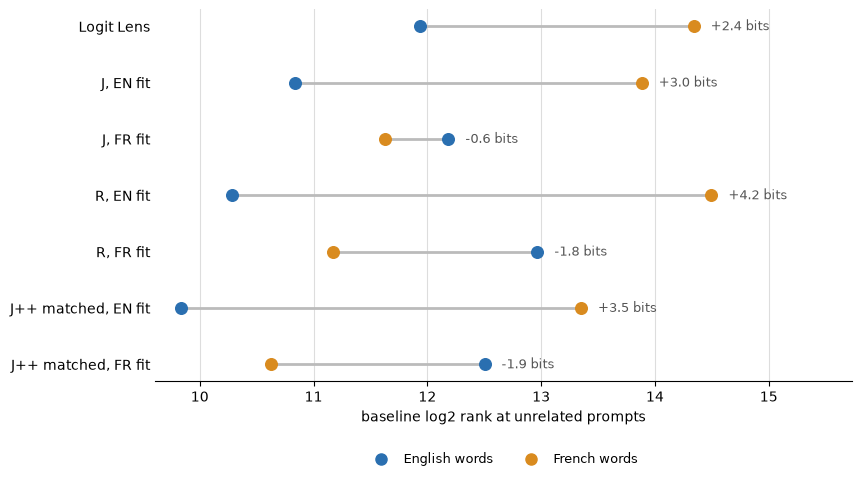

In [41]:
point, _ = result["baseline"]
lines = [("logit", "none", "Logit Lens")] + [(lens, fit, f"{LENS_NAMES[lens]}, {fit.upper()} fit")
         for lens in ("j", "r", "jpp_matched") for fit in ("en", "fr")]
figure, axis = plt.subplots(figsize=(8.5, 0.5 * len(lines) + 1.2), constrained_layout=True)
for y, (lens, fit, label) in zip(range(len(lines))[::-1], lines):
    english = (point[(lens, fit, "en", "en")] + point[(lens, fit, "fr", "en")]) / 2     # mean of the two prompt languages
    french = (point[(lens, fit, "en", "fr")] + point[(lens, fit, "fr", "fr")]) / 2
    axis.plot([english, french], [y, y], color="#bbbbbb", linewidth=2, zorder=1)
    axis.scatter([english], [y], color=BLUE, s=70, zorder=2)
    axis.scatter([french], [y], color=ORANGE, s=70, zorder=2)
    axis.text(max(english, french) + 0.15, y, f"{french - english:+.1f} bits", va="center", fontsize=9, color="#555555")
axis.set_yticks(range(len(lines))[::-1], [label for *_, label in lines], fontsize=10)
axis.set_xlabel("baseline log2 rank at unrelated prompts", fontsize=10)
axis.set_xlim(right=axis.get_xlim()[1] + 1.0)
clean(axis)
axis.legend(handles=[plt.Line2D([], [], color=c, marker="o", linestyle="", markersize=8, label=n)
                     for n, c in (("English words", BLUE), ("French words", ORANGE))],
            frameon=False, fontsize=9, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.16))
save(figure, "fig2_default_vocabulary")

EN domain           FR domain  \
lens           score                                             
J              rank      1.74 [1.21, 2.32]   3.48 [2.85, 4.12]   
               lift     0.44 [-0.14, 1.06]   1.43 [0.87, 2.04]   
R              rank      1.83 [1.37, 2.30]   3.40 [3.05, 3.76]   
               lift   -0.72 [-1.23, -0.17]  0.31 [-0.11, 0.74]   
J++ matched    rank      2.60 [1.94, 3.35]   3.46 [2.77, 4.12]   
               lift     0.10 [-0.57, 0.91]   1.08 [0.46, 1.74]   
J++ EN weights rank      1.38 [0.73, 2.16]   2.45 [1.82, 3.06]   
               lift    -0.32 [-0.94, 0.45]  0.39 [-0.17, 1.00]   
J++ FR weights rank      1.35 [0.66, 2.14]   4.00 [3.23, 4.82]   
               lift   -0.94 [-1.74, -0.05]   1.19 [0.36, 2.03]   
J++ original   rank      1.52 [0.89, 2.19]   3.33 [2.74, 3.91]   
               lift    -0.51 [-1.12, 0.18]  0.42 [-0.13, 1.00]   

                                     mean          mean minus J  
lens           score                                             
J              rank     2.61 [2.20, 3.00]                        
               lift     0.94 [0.56, 1.32]                        
R              rank     2.61 [2.35, 2.88]  +0.00 [-0.27, +0.30]  
               lift   -0.20 [-0.55, 0.14]  -1.14 [-1.40, -0.89]  
J++ matched    rank     3.03 [2.56, 3.51]  +0.42 [-0.03, +0.84]  
               lift     0.59 [0.15, 1.04]  -0.35 [-0.74, +0.04]  
J++ EN weights rank     1.92 [1.47, 2.43]  -0.70 [-1.21, -0.15]  
               lift    0.04 [-0.35, 0.46]  -0.90 [-1.34, -0.45]  
J++ FR weights rank     2.67 [2.19, 3.16]  +0.06 [-0.43, +0.54]  
               lift    0.13 [-0.38, 0.66]  -0.81 [-1.27, -0.37]  
J++ original   rank     2.42 [2.08, 2.79]  -0.19 [-0.58, +0.21]  
               lift   -0.05 [-0.38, 0.32]  -0.98 [-1.31, -0.66]

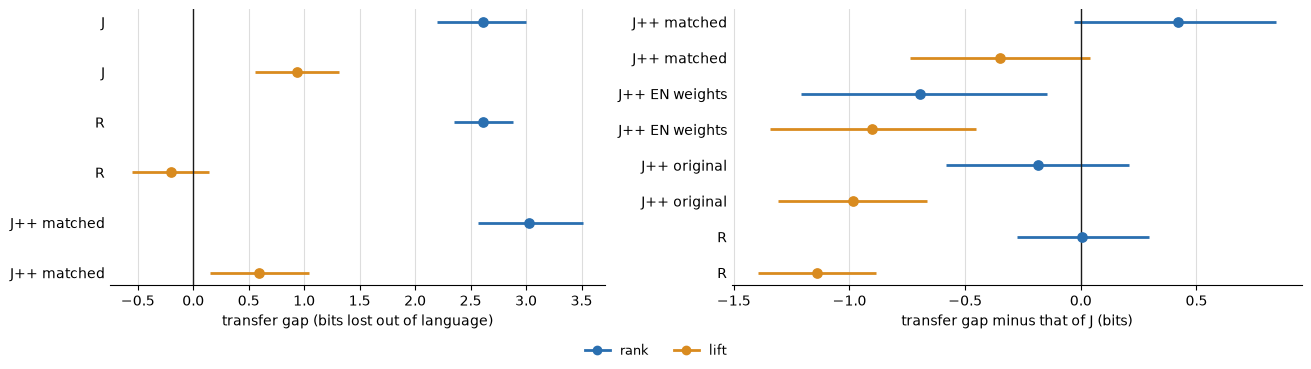

In [42]:
def transfer_gap(score, lens, sign=1):
    # Bits lost out of language: other-language lens minus own-language lens, per domain and on average
    point, draws = result[score]
    gaps = {}
    for d in ("en", "fr"):
        own, other = (lens, d, d, d), (lens, OTHER[d], d, d)
        gaps[d] = (sign * (point[other] - point[own]), sign * (draws[other] - draws[own]))
    gaps["mean"] = ((gaps["en"][0] + gaps["fr"][0]) / 2, (gaps["en"][1] + gaps["fr"][1]) / 2)
    return gaps

# lift is "higher is better", so its sign is flipped to keep "bits lost"
gaps = {score: {lens: transfer_gap(score, lens, sign) for lens in LENS_NAMES} for score, sign in (("log_rank", 1), ("lift", -1))}
SCORE_STYLE = {"log_rank": ("rank", BLUE), "lift": ("lift", ORANGE)}

def forest(axis, rows):
    # rows: list of (label, score, interval dict), drawn top to bottom
    for y, (label, score, entry) in zip(range(len(rows))[::-1], rows):
        color = SCORE_STYLE[score][1]
        axis.hlines(y, entry["low"], entry["high"], color=color, linewidth=2)
        axis.scatter([entry["value"]], [y], color=color, s=45, zorder=3)
    axis.axvline(0, color=INK, linewidth=1)
    axis.set_yticks(range(len(rows))[::-1], [label for label, *_ in rows], fontsize=10)
    clean(axis)

gap_rows = [(f"{LENS_NAMES[lens]}", score, interval(*gaps[score][lens]["mean"]))
            for lens in ("j", "r", "jpp_matched") for score in SCORE_STYLE]
h1_rows = [(f"{LENS_NAMES[lens]}", score, interval(gaps[score][lens]["mean"][0] - gaps[score]["j"]["mean"][0],
                                                   gaps[score][lens]["mean"][1] - gaps[score]["j"]["mean"][1]))
           for lens in ("jpp_matched", "jpp_wen", "jpp", "r") for score in SCORE_STYLE]

figure, axes = plt.subplots(1, 2, figsize=(13, 3.6), constrained_layout=True, gridspec_kw={"width_ratios": [1, 1.15]})
forest(axes[0], gap_rows)
axes[0].set_xlabel("transfer gap (bits lost out of language)", fontsize=10)
forest(axes[1], h1_rows)
axes[1].set_xlabel("transfer gap minus that of J (bits)", fontsize=10)
figure.legend(handles=[plt.Line2D([], [], color=c, marker="o", linewidth=2, label=n) for n, c in SCORE_STYLE.values()],
              frameon=False, fontsize=9, ncol=2, loc="outside lower center")
save(figure, "fig3_transfer_gap_and_h1")

table2 = pd.DataFrame([{"lens": LENS_NAMES[lens], "score": SCORE_STYLE[score][0], "EN domain": text(interval(*gaps[score][lens]["en"])),
                        "FR domain": text(interval(*gaps[score][lens]["fr"])), "mean": text(interval(*gaps[score][lens]["mean"])),
                        "mean minus J": "" if lens == "j" else text(interval(gaps[score][lens]["mean"][0] - gaps[score]["j"]["mean"][0],
                                                                             gaps[score][lens]["mean"][1] - gaps[score]["j"]["mean"][1]), signed=True)}
                       for lens in LENS_NAMES for score in SCORE_STYLE]).set_index(["lens", "score"])
table2.to_csv(FIGURES / "table2_transfer_gap.csv")
table2

**Analysis.** Figure 2: under English-fitted lenses, French words start 2.7 to 4.1 bits behind English ones before any prompt is read; under French-fitted lenses the order flips (−0.4 to −1.5 bits). The Logit Lens already has a 2.3-bit preference for English. J++ has the widest spread.

Figure 3, left: in rank, every lens loses 1.4 to 2.5 bits out of language. In lift the gap falls to 0.49 [0.17, 0.83] for J and to about zero for J++ (0.07 [−0.27, 0.43]); for R it is negative. Right: in rank, J++ with matched weights loses 0.81 bits [0.39, 1.25] more than J, while the same expert Jacobians with English-label weights or the original weights do not differ detectably from J. In lift, no J++ variant transfers worse than J.

**Key points**
- Fitting language mainly sets which language's words a lens ranks high **by default**. This prior accounts for most of the transfer gap.
- What a lens reads from a given prompt transfers across languages almost fully.
- **H1 depends on the metric.** In rank, J++ generalises less than J (+0.81 bits), and the cause is its supervised weights. In lift it does not.
- Practical consequence: an English-fitted lens is still unusable for French readout, because the French word starts too far down the list.
- Caveat: the control words are other items' targets, so lift gives no credit for promoting content words in general. Rank measures usability, lift measures specificity.

## 5. Stated versus inferred concepts (Figure 4, Table 3)

The French multilingual items carry four intermediates with different roles. All prompts are French. Blue: recall of the English word; orange: of the French word. Table 3 then tests, on the parallel items, whether a French prompt's hidden state says more about the English word than about the French one, using lift so that token frequency is controlled.

n items EN targets: EN fit - FR fit  \
role                    lens                                               
language name           J                 12               +17 [+0, +42]   
                        R                 12                 +0 [+0, +0]   
                        J++ matched       12              +67 [+42, +92]   
category (inferred)     J                 11               +18 [+0, +45]   
                        R                 11               +27 [+0, +55]   
                        J++ matched       11               +18 [+0, +45]   
operand (in the prompt) J                 11              +64 [+36, +91]   
                        R                 11              +64 [+36, +91]   
                        J++ matched       11              +55 [+27, +82]   
answer (next word)      J                 11                +9 [+0, +27]   
                        R                 11                +9 [+0, +27]   
                        J++ matched       11               +36 [+9, +64]   

                                    FR targets: EN fit - FR fit  
role                    lens                                     
language name           J                           +0 [+0, +0]  
                        R                           +0 [+0, +0]  
                        J++ matched                -8 [-25, +0]  
category (inferred)     J                         -27 [-55, +0]  
                        R                         -27 [-55, +0]  
                        J++ matched              -45 [-73, -18]  
operand (in the prompt) J                         -36 [-64, -9]  
                        R                         -18 [-45, +0]  
                        J++ matched               -18 [-45, +0]  
answer (next word)      J                       -82 [-100, -55]  
                        R                        -64 [-91, -36]  
                        J++ matched              -55 [-82, -27]

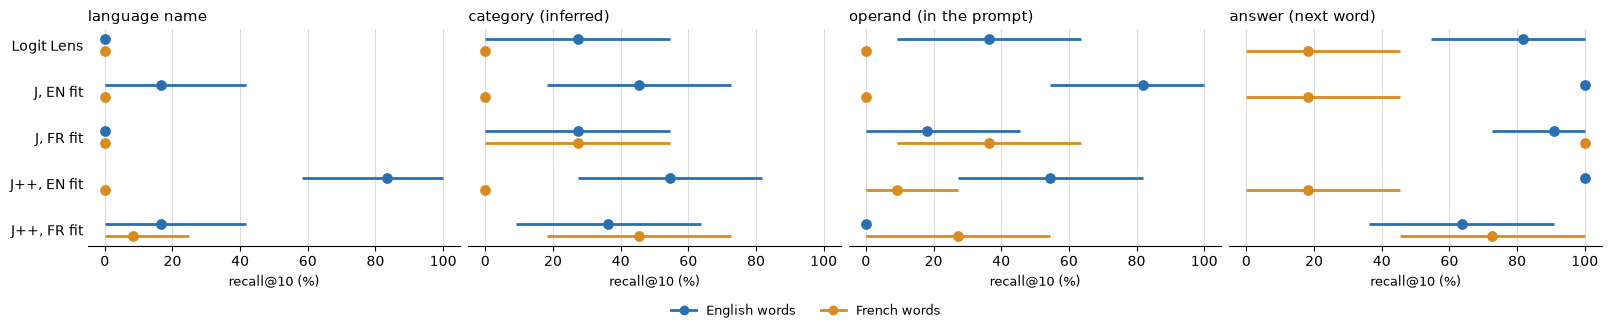

In [43]:
POSITIONS = {0: "language name", 1: "category (inferred)", 2: "operand (in the prompt)", 3: "answer (next word)"}
READERS = [("logit", "none", "Logit Lens"), ("j", "en", "J, EN fit"), ("j", "fr", "J, FR fit"),
           ("jpp_matched", "en", "J++, EN fit"), ("jpp_matched", "fr", "J++, FR fit")]

multilingual = scored[scored["group"] == "fr-multilingual"]
figure, axes = plt.subplots(1, 4, figsize=(16, 3.2), sharey=True, constrained_layout=True)
crossover = []
for axis, (position, role) in zip(axes, POSITIONS.items()):
    part = add_matched(multilingual[multilingual["position"] == position]
                       .groupby(["eval", "item"] + RUN + CONDITION, as_index=False)["hit"].mean())
    point, draws = bootstrap(part, "hit")
    for y, (lens, fit, _) in zip(range(len(READERS))[::-1], READERS):
        for target, color, offset in (("en", BLUE, 0.13), ("fr", ORANGE, -0.13)):
            cell = (lens, fit, "fr", target)
            axis.hlines(y + offset, draws[cell].quantile(0.025) * 100, draws[cell].quantile(0.975) * 100, color=color, linewidth=2)
            axis.scatter([point[cell] * 100], [y + offset], color=color, s=45, zorder=3)
    for lens in ("j", "r", "jpp_matched"):
        crossover.append({"role": role, "lens": LENS_NAMES[lens], "n items": part["item"].nunique(),
                          **{f"{t.upper()} targets: EN fit - FR fit": text({k: v * 100 for k, v in difference((point, draws), (lens, "en", "fr", t), (lens, "fr", "fr", t)).items()}, 0, True)
                             for t in ("en", "fr")}})
    axis.set_title(role, fontsize=11, loc="left")
    axis.set_xlim(-5, 105)
    axis.set_xlabel("recall@10 (%)", fontsize=9)
    clean(axis)
axes[0].set_yticks(range(len(READERS))[::-1], [label for *_, label in READERS], fontsize=10)
figure.legend(handles=[plt.Line2D([], [], color=c, marker="o", linewidth=2, label=n) for n, c in (("English words", BLUE), ("French words", ORANGE))],
              frameon=False, fontsize=9, ncol=2, loc="outside lower center")
save(figure, "fig4_word_roles")
pd.DataFrame(crossover).set_index(["role", "lens"])

In [44]:
table3 = pd.DataFrame([{"lens": label, "lift of EN word - lift of FR word (bits)": text(difference(result["lift"], (lens, fit, "fr", "en"), (lens, fit, "fr", "fr")), signed=True)}
                       for lens, fit, label in [("logit", "none", "Logit Lens"), ("j", "fr", "J, FR fit"), ("r", "fr", "R, FR fit"), ("jpp_matched", "fr", "J++ matched, FR fit")]]).set_index("lens")
table3.to_csv(FIGURES / "table3_english_lean.csv")
table3

,lift of EN word - lift of FR word (bits)
lens,
Logit Lens,"+2.51 [+1.43, +3.66]"
"J, FR fit","+1.07 [+0.32, +1.85]"
"R, FR fit","+2.31 [+1.58, +3.07]"
"J++ matched, FR fit","+1.71 [+0.93, +2.55]"


**Analysis.** For the **operand**, a word written in the prompt, the two J lenses read the same hidden states in two languages at similar rates: the English-fitted one finds *night* in about 73% of items and the French-fitted one finds *nuit* in about 64%, each near zero on the other language (+68 [+41, +91] points on English targets, −55 [−82, −27] on French). For the **category**, which must be inferred, English-fitted lenses reach about 60% on the English word while French-fitted lenses reach 10 to 35% on the French one. The **answer** is found by nearly every lens and says nothing about transfer. The **language name** is found only by J++ with English weights.

Table 3: on French prompts, every lens gives the English word more lift than the French one, including French-fitted lenses: +0.73 bits [0.01, 1.44] for the Logit Lens, +1.05 [0.36, 1.75] for J, about +1.8 for R and J++.

**Key points**
- The operand gives the cleanest double dissociation: same prompts, each lens reads its own language.
- For a stated word, French readout matches English readout. For an inferred concept, English is favoured.
- The English lean survives the token-frequency control, so it is not just French tokens being rarer. The Logit Lens interval only just excludes zero.
- These rest on 10 or 11 items per role; treat the role-level result as indicative.

## 6. Evidence without labels (Figures 5 and 6, 9B only)

These measurements use no benchmark targets. **Figure 5**: how different two lenses are, in parameters (1 − cosine of the Jacobians) and in output (symmetric KL of their token distributions), for pairs that differ by pool (noise), corpus or language. **Figure 6**: KL from the model's own next-token distribution to the lens, by fitting corpus and by the text it is applied to; the small number is how much pools A and B disagree.

In [45]:
SCORES_DIR = ROOT / "scores"
HAS_DISTANCES = (SCORES_DIR / "compare.csv").is_file()

def load_distances(path):
    frame = pd.read_csv(path)
    frame = pd.concat([frame, frame["pair"].str.extract(r"^(?P<kind>.+?)_n(?P<size>\d+)_(?P<lens>.+)$")], axis=1)
    frame["family"] = frame["kind"].str.extract(r"^(noise|corpus|language|mixed|converge|method|weights)")[0]
    frame["kl_sym"] = (frame["kl_a_b"] + frame["kl_b_a"]) / 2
    return frame[frame["size"] == "1000"]

if HAS_DISTANCES:
    distances = load_distances(SCORES_DIR / "compare.csv")
    level = distances[distances["family"].isin(["noise", "corpus", "language"]) & distances["lens"].isin(["j", "r", "jpp"])].copy()
    level["distance"] = 1 - level["cosine"]
    FAMILY = {"noise": GREY, "corpus": ORANGE, "language": BLUE}

    figure, axes = plt.subplots(1, 2, figsize=(13, 3.2), sharey=True, constrained_layout=True)
    panels = [(level[level["samples"] == "eval"], "distance", "1 - cosine of the Jacobians"),
              (level[level["samples"].isin(["en", "fr"])], "kl_sym", "symmetric KL on EN and FR text (nats)")]
    for axis, (frame, value, xlabel) in zip(axes, panels):
        for i, lens in enumerate(["j", "r", "jpp"]):
            for k, (family, color) in enumerate(FAMILY.items()):
                part = frame[(frame["lens"] == lens) & (frame["family"] == family)][value]
                y = 2 - i + (1 - k) * 0.25
                axis.scatter(part, np.full(len(part), y), color=color, s=12, alpha=0.35, zorder=2)                 # one layer of one pair
                axis.scatter([part.mean()], [y], color=color, s=80, edgecolor="white", linewidth=1.5, zorder=3)    # mean
        axis.set_xscale("log")
        axis.set_xlabel(xlabel, fontsize=10)
        clean(axis)
    axes[0].set_yticks([2, 1, 0], ["J", "R", "J++"], fontsize=10)
    figure.legend(handles=[plt.Line2D([], [], color=c, marker="o", linestyle="", markersize=8, label=n) for n, c in FAMILY.items()],
                  frameon=False, fontsize=9, ncol=3, loc="outside lower center")
    save(figure, "fig5_lens_distances")
    display(level[level["samples"] == "eval"].groupby(["lens", "family"])[["distance", "kl_sym"]].mean().unstack("family").round(3))
else:
    print("No scores/ folder: section 6 skipped.")

No scores/ folder: section 6 skipped.


In [46]:
if HAS_DISTANCES:
    noise = distances[(distances["family"] == "noise") & distances["lens"].isin(["j", "r", "jpp"]) & (distances["samples"] != "eval")].copy()
    noise["fit"] = noise["kind"].str.replace("noise-", "")
    noise["kl_model"] = (noise["kl_model_a"] + noise["kl_model_b"]) / 2
    noise["pool_gap"] = (noise["kl_model_a"] - noise["kl_model_b"]).abs()
    order = ["wikitext", "en", "fr"]
    closeness = noise.groupby(["lens", "fit", "samples"])["kl_model"].mean().unstack("samples").reindex(columns=order)
    pool_gap = noise.groupby(["lens", "fit", "samples"])["pool_gap"].mean().unstack("samples").reindex(columns=order)

    figure, axes = plt.subplots(1, 3, figsize=(13, 3.0), constrained_layout=True)
    for axis, (lens, name) in zip(axes, [("j", "J"), ("r", "R"), ("jpp", "J++")]):
        grid = closeness.loc[lens].reindex(order)
        shade = 1 - (grid - grid.values.min()) / (grid.values.max() - grid.values.min())     # darker = closer to the model, per panel
        axis.imshow(shade, cmap="Blues", vmin=0, vmax=1.25, aspect="auto")
        for i, fit in enumerate(order):
            for j, probe in enumerate(order):
                ink = "white" if shade.iloc[i, j] > 0.6 else INK
                axis.text(j, i - 0.08, f"{grid.loc[fit, probe]:.2f}", ha="center", va="center", fontsize=13, color=ink,
                          fontweight="bold" if fit == probe else "normal")
                axis.text(j, i + 0.27, f"± {pool_gap.loc[(lens, fit), probe]:.2f}", ha="center", va="center", fontsize=8, color=ink)
        axis.set_xticks(range(3), ["WikiText text", "EN Wiki text", "FR Wiki text"], fontsize=9)
        axis.xaxis.tick_top()
        axis.set_yticks(range(3), ["WikiText fit", "EN Wiki fit", "FR Wiki fit"], fontsize=10)
        axis.set_xticks(np.arange(-0.5, 3), minor=True)
        axis.set_yticks(np.arange(-0.5, 3), minor=True)
        axis.grid(which="minor", color="white", linewidth=3)
        axis.tick_params(which="both", length=0)
        for spine in axis.spines.values():
            spine.set_visible(False)
        axis.set_title(name, fontsize=13, fontweight="bold", pad=22)
    save(figure, "fig6_kl_to_model")

    weights = load_distances(SCORES_DIR / "compare_weights.csv")
    weights = weights[(weights["samples"] == "eval") & (weights["family"] == "weights")]
    print("J++ lenses sharing the same expert Jacobians, differing only in weights: cosine")
    print(weights.groupby("lens")["cosine"].agg(["mean", "min", "max"]).round(2).to_string())

**Analysis.** Figure 5: for J and R, two fits of the same lens are nearly identical (1 − cosine of 0.005 and 0.002, KL of 0.01 to 0.04), while corpus and language pairs are 20 to 50 times further apart; language is about 1.5 to 2.7 times corpus. For J++ the three kinds of pair overlap (noise 0.21, corpus 0.32, language 0.29).

Figure 6: R shows a clean diagonal, the lens fitted in a text's language being closest to the model on that text (4.69 against 6.44 on English, 5.02 against 7.12 on French). J is asymmetric: the French-fitted lens wins on French text (7.55 against 9.42) and ties on English text (8.16 against 8.22). For J++ the two pools disagree by 0.6 to 1.6 nats, as much as the effects.

Two J++ lenses built from the **same** expert Jacobians with different weights have a mean cosine of about 0.71, as low as −0.14 at one layer: as different as lenses fitted on different languages.

**Key points**
- The language effect on J and R is confirmed without any benchmark, at the parameter and readout levels.
- The label-free J result has the same shape as the lift result: an English-fitted lens loses on French, a French-fitted lens loses little on English.
- J++ cannot be studied at these two levels: its fit-to-fit variation is as large as the effects. The supervised weights are the unstable component.

## 7. Summary of claims

| Claim | Evidence | Strength |
|---|---|---|
| A lens reads the vocabulary of its fitting language | Fig. 1; Table 1 (2 to 3 bits on French); Fig. 4 operand | Strong, both models |
| Most of the transfer gap is a default-vocabulary prior | Fig. 2; Fig. 3 left (gap 1.4–2.5 bits in rank, about 0–0.5 in lift) | Strong, with the caveat on lift |
| J++ generalises less than J (H1) | Fig. 3 right: +0.81 bits [0.39, 1.25] in rank, not in lift; due to supervised weights | Supported in rank only |
| The hidden state leans towards English | Fig. 1 Logit Lens row; Table 3 (+0.7 to +1.9 bits of lift) | Moderate |
| Stated words are read symmetrically, inferred concepts favour English | Fig. 4 | Indicative (10–11 items) |
| J++ is less reproducible than J and R | Table 1 noise; Fig. 5; Fig. 6; weights-only cosine 0.71 | Strong |
| The language effect is about twice a same-language corpus change | Table 1; Fig. 5 | Moderate, depends on the sample set |

**Limits to state in the report.** One main model (9B), with 27B at 64 prompts and one pool as a directional check. 40 parallel items. French targets restricted to single-token, hence more frequent, words. French prompts were translated for this study. Lift uses control words of the same kind as the targets.